# %CFE 7-day forecasting: naive baselines and an XGBoost benchmark

**Goal:** set the bar that every 7-day %CFE forecast has to beat, using two forecasts that need no training and one simple model trained on lags only.

- **Target:** %CFE = 100 · (nuclear + hydro + solar + wind + geothermal) / total generation, per UTC hour. Data: `CarbonCast/data/<R>/<R>_lifecycle_emissions.csv`, 2020–2021.
- **Forecast:** one per day. A forecast starting at 00:00 UTC on day *D* knows everything up to 23:00 on day *D* − 1 and covers the next 168 hours, days *D* to *D* + 6. Forecast day *k* is hours 24(*k* − 1) + 1 to 24*k*.
- **Naive baselines:**
  - **Last day:** the same hour on the last observed day. Yesterday's 24-hour profile is repeated for all 7 days.
  - **7-day mean:** the mean of the same hour over the last 7 observed days. The average profile of the past week is repeated for all 7 days.
- **XGBoost:** gradient-boosted trees on the past week of %CFE and the calendar. No weather.
- **Test period:** forecasts starting 1 Jul – 25 Dec 2021, so every target hour falls in Jul–Dec 2021, the test half-year used by CarbonCast.

Later models go into the same `forecasts` dictionary and are scored by the same functions.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import xgboost as xgb

COLORS = {"last day": "#2a78d6", "7-day mean": "#eb6834", "XGBoost": "#1baf7a"}     # one fixed colour per model, in every chart
INK, MUTED, AXIS, GRID, SURFACE = "#52514e", "#898781", "#c3c2b7", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10, "text.color": "#0b0b0b",
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "lines.linewidth": 1.8, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False,
})

## 1. Parameters

In [2]:
REGION = "DE"
INCLUDE_BIOMASS_AS_CFE = False      # definitions differ; keep it explicit
CFE_SOURCES = ["nuclear", "hydro", "solar", "wind", "geothermal"] + (["biomass"] if INCLUDE_BIOMASS_AS_CFE else [])

HORIZON_DAYS = 7                    # forecast window in days
START_HOUR = 0                      # UTC hour at which each forecast window starts (one forecast per day)
VAL_START = "2021-01-01"            # XGBoost trains on targets before this date and picks its number of trees on VAL_START to TEST_START
TEST_START, TEST_END = "2021-07-01", "2022-01-01"   # test forecasts start from TEST_START; every target hour is before TEST_END
EXAMPLE_START = "2021-10-04"        # the forecast drawn in section 6

XGB_PARAMS = dict(learning_rate=0.05, max_depth=6, min_child_weight=20, subsample=0.8, colsample_bytree=0.8,
                  tree_method="hist", random_state=0, n_jobs=-1)
MAX_TREES, PATIENCE = 3000, 50      # early stopping

H = 24 * HORIZON_DAYS               # hours to predict
HIST = 24 * 7                       # hours of history each forecast is given

ROOT = Path.cwd()
DATA_DIR = ROOT / "CarbonCast" / "data"
OUT_DIR = ROOT / "results" / "cfe_7day_baseline"
assert DATA_DIR.exists(), "Run from the repo root, after `git submodule update --init`."

## 2. The %CFE series

Negative generation is set to zero, gaps of up to 3 hours are interpolated and longer ones carried forward. %CFE is then the carbon-free share of total generation.

In [3]:
def load_cfe(region, cfe_sources=CFE_SOURCES):
    df = pd.read_csv(DATA_DIR / region / f"{region}_lifecycle_emissions.csv")
    df.index = pd.to_datetime(df.pop("UTC time"), utc=True).dt.tz_localize(None)   # some files carry +00:00
    sources = [c for c in df.columns if c != "carbon_intensity" and not c.startswith("Unnamed")]
    gen = df[sources].clip(lower=0)
    gen = gen[~gen.index.duplicated()].asfreq("h").interpolate(limit=3).ffill()
    total = gen.sum(axis=1).replace(0, np.nan)
    cfe = gen[[c for c in sources if c in cfe_sources]].sum(axis=1) / total * 100
    return cfe.ffill().rename("cfe")

cfe = load_cfe(REGION)
print(f"{REGION}: {len(cfe):,} hours, {cfe.index[0]} to {cfe.index[-1]}, mean %CFE {cfe.mean():.1f}")

DE: 17,544 hours, 2020-01-01 00:00:00 to 2021-12-31 23:00:00, mean %CFE 49.3


## 3. Forecast windows

`make_windows` returns one row per forecast: its start time, the 168 hours before it (`history`) and the 168 hours to predict (`actual`). Every forecast is built from `history` alone. Scoring uses forecasts starting at `START_HOUR`; `start_hour=None` returns a window for every hour, which XGBoost uses for training.

In [4]:
def make_windows(cfe, start=TEST_START, end=TEST_END, start_hour=START_HOUR):
    y, idx = cfe.to_numpy(), cfe.index
    ok = (idx >= pd.Timestamp(start)) & (idx + pd.Timedelta(hours=H) <= pd.Timestamp(end))
    if start_hour is not None:
        ok &= idx.hour == start_hour
    pos = np.flatnonzero(ok)
    pos = pos[(pos >= HIST) & (pos + H <= len(y))]
    history = y[pos[:, None] + np.arange(-HIST, 0)]
    actual = y[pos[:, None] + np.arange(H)]
    return idx[pos], history, actual

starts, history, actual = make_windows(cfe)
print(f"{len(starts)} forecasts, starting {starts[0]} to {starts[-1]}; last target hour {starts[-1] + pd.Timedelta(hours=H - 1)}")

178 forecasts, starting 2021-07-01 00:00:00 to 2021-12-25 00:00:00; last target hour 2021-12-31 23:00:00


## 4. The two naive baselines

For a target hour τ on forecast day *k*:

- **Last day:** ŷ(τ) = y(τ − 24*k*)
- **7-day mean:** ŷ(τ) = mean of y(τ − 24(*k* + *d*)) for *d* = 0…6

In [ ]:
def last_day(history):
    return np.tile(history[:, -24:], HORIZON_DAYS)

def mean_7d(history):
    profile = history.reshape(len(history), 7, 24).mean(axis=1)     
    return np.tile(profile, HORIZON_DAYS)

NAIVE = {"last day": last_day, "7-day mean": mean_7d}
forecasts = {name: f(history) for name, f in NAIVE.items()}

## 5. XGBoost on lags

- **What it predicts:** the correction to the 7-day mean, y(τ) − 7-day mean. The forecast is the 7-day mean plus that correction, clipped to 0–100, so with nothing to learn the model falls back to the baseline.
- **Two models:** one for day 1 (hours 1–24) and one for days 2–7, each with the hours ahead as a feature.
- **Training:** on forecasts starting at every hour of the day, not only `START_HOUR`. The number of trees is chosen by early stopping: train on windows whose targets end before `VAL_START`, stop when the error on windows from `VAL_START` to `TEST_START` stops improving. The model is then refitted on everything before `TEST_START` with that number of trees.

| Features (46) | |
|---|---|
| last day against the weekly profile (24) | each of the last 24 hours minus the 7-day mean of that hour |
| level and spread (9) | mean of each of the last 7 days; standard deviation of the last 24 hours and of the last 7 days |
| target hour (8) | %CFE at the same hour on each of the last 7 days, and their mean (the 7-day-mean forecast) |
| calendar (5) | hours ahead; hour of day, day of week and day of year (sin, cos) of the target |

**Choices checked on validation forecasts (Jan–Jun 2021), without using the test period:**
- One model for all 168 hours was worse than *last day* on day 1 in the three regions tried (DE, CISO, NYISO).
- Predicting %CFE itself instead of the correction was worse than the 7-day mean in SE (0.95 against 0.81 pp).
- One model per forecast day, source-mix shares and 28-day means gave no consistent gain over this setup (DE, CISO, NYISO, ERCO, SE).
- One model per hour for day 1 lowered the day-1 error by a further 1–8 % in those five regions, for 24 extra models. Left out to keep this simple.
- Refitting on train + validation helped in 4 of the 5, checked on an earlier split.

In [6]:
BLOCKS = {"day 1": (1, 24), f"days 2-{HORIZON_DAYS}": (25, H)}      # hours ahead covered by each model

def make_features(starts, history):
    # One row per (forecast, hour ahead), forecasts in order, hours 1..H within each forecast.
    n = len(starts)
    days = history.reshape(n, 7, 24)                                # [forecast, day (oldest first), hour]
    profile = days.mean(axis=1)                                     # 7-day mean by hour
    per_forecast = np.hstack([
        history[:, -24:] - profile,                                 # last day against the weekly profile
        days.mean(axis=2),                                          # mean of each of the last 7 days
        history[:, -24:].std(axis=1, keepdims=True), history.std(axis=1, keepdims=True)])
    same_hour = days[:, ::-1][:, :, np.arange(H) % 24].transpose(0, 2, 1)     # (n, H, 7): 1, 2, ... 7 days before day 1
    target = pd.DatetimeIndex((starts.values[:, None] + np.arange(H).astype("timedelta64[h]")).ravel())
    angle = 2 * np.pi * target.day_of_year / 365.25
    per_hour = np.column_stack([
        np.tile(np.arange(1, H + 1), n), same_hour.reshape(n * H, 7), mean_7d(history).ravel(),
        target.hour, target.day_of_week, np.sin(angle), np.cos(angle)])
    return np.hstack([np.repeat(per_forecast, H, axis=0), per_hour]).astype(np.float32)

def block_rows(block, n_forecasts):
    lo, hi = BLOCKS[block]
    hours_ahead = np.arange(1, H + 1)
    return np.tile((hours_ahead >= lo) & (hours_ahead <= hi), n_forecasts)

def fit_xgb(cfe):
    starts, history, actual = make_windows(cfe, cfe.index[0], TEST_START, start_hour=None)
    X, y = make_features(starts, history), (actual - mean_7d(history)).ravel()
    train = np.repeat(starts + pd.Timedelta(hours=H) <= pd.Timestamp(VAL_START), H)
    val = np.repeat(starts >= pd.Timestamp(VAL_START), H)
    models = {}
    for block in BLOCKS:
        rows = block_rows(block, len(starts))
        stopper = xgb.XGBRegressor(n_estimators=MAX_TREES, early_stopping_rounds=PATIENCE, eval_metric="mae", **XGB_PARAMS)
        stopper.fit(X[rows & train], y[rows & train], eval_set=[(X[rows & val], y[rows & val])], verbose=False)
        models[block] = xgb.XGBRegressor(n_estimators=stopper.best_iteration + 1, **XGB_PARAMS).fit(X[rows], y[rows])
    return models

def xgb_forecast(models, starts, history):
    X = make_features(starts, history)
    correction = np.empty(len(X))
    for block, model in models.items():
        rows = block_rows(block, len(starts))
        correction[rows] = model.predict(X[rows])
    return np.clip(mean_7d(history) + correction.reshape(len(starts), H), 0, 100)

models = fit_xgb(cfe)
print("trees:", {block: m.n_estimators for block, m in models.items()})
forecasts["XGBoost"] = xgb_forecast(models, starts, history)

trees: {'day 1': 68, 'days 2-7': 44}


## 6. Results for one region

Errors are forecast − actual, in percentage points of %CFE. **MAE**, **RMSE** and **bias** (mean error) are given for each forecast day and for the whole window (`all`).

**Best naive** is the bar for a model: on each forecast day, the lower MAE of the two naive baselines; its `all` is the mean over the 7 days.

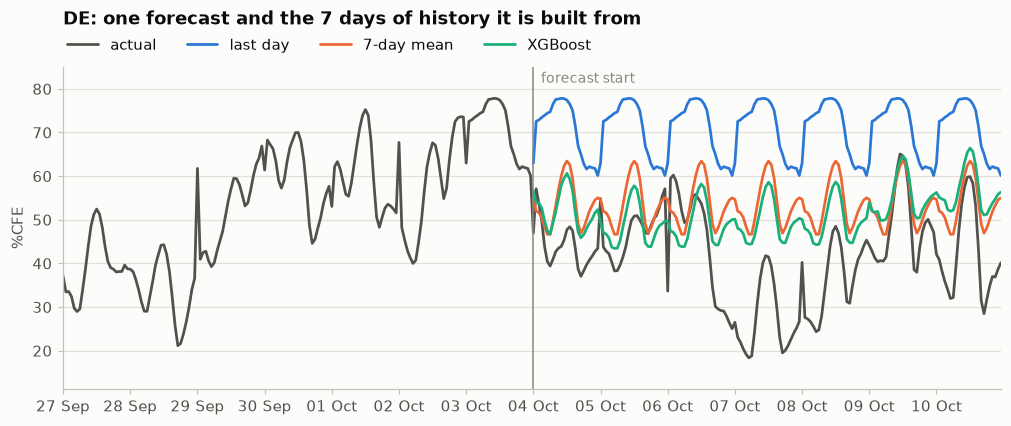

In [7]:
i = starts.get_loc(pd.Timestamp(EXAMPLE_START))
past = pd.date_range(end=starts[i], periods=HIST + 1, freq="h")[:-1]
future = pd.date_range(starts[i], periods=H, freq="h")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(past.append(future), np.r_[history[i], actual[i]], color=INK, label="actual")
for name, p in forecasts.items():
    ax.plot(future, p[i], color=COLORS[name], label=name)
ax.axvline(starts[i], color=MUTED, linewidth=1)
ax.annotate("forecast start", (starts[i], 1), xycoords=("data", "axes fraction"), xytext=(5, -3),
            textcoords="offset points", va="top", color=MUTED, fontsize=9)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.margins(x=0, y=0.12)
ax.set_ylabel("%CFE")
ax.set_title(f"{REGION}: one forecast and the 7 days of history it is built from", pad=28)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(-0.01, 1.0))
plt.show()

In [8]:
DAYS = [f"day {k}" for k in range(1, HORIZON_DAYS + 1)] + ["all"]

def score(actual, forecast):
    e = (forecast - actual).reshape(len(actual), HORIZON_DAYS, 24)
    per_day = lambda f: [f(e[:, k]) for k in range(HORIZON_DAYS)] + [f(e)]
    return pd.DataFrame({"MAE": per_day(lambda x: np.abs(x).mean()),
                         "RMSE": per_day(lambda x: np.sqrt((x ** 2).mean())),
                         "bias": per_day(np.mean)}, index=DAYS).T

scores = pd.concat({name: score(actual, p) for name, p in forecasts.items()}, names=["model", "metric"])
by_metric = pd.MultiIndex.from_product([["MAE", "RMSE", "bias"], list(forecasts)], names=["metric", "model"])
display(scores.swaplevel().reindex(by_metric).round(2))

mae = scores.xs("MAE", level="metric")
bar = mae.loc[list(NAIVE)].min()
bar["all"] = bar[DAYS[:-1]].mean()
display(pd.DataFrame({"best naive, MAE (pp)": bar, "XGBoost, MAE (pp)": mae.loc["XGBoost"],
                      "XGBoost against best naive (%)": (mae.loc["XGBoost"] / bar - 1) * 100}).T.round(2))

day 1  day 2  day 3  day 4  day 5  day 6  day 7    all
metric model                                                             
MAE    last day     9.14  11.80  12.85  13.60  13.17  13.16  12.30  12.29
       7-day mean   9.43   9.87  10.05  10.09   9.89   9.88  10.08   9.90
       XGBoost      6.48   9.73   9.84   9.61   9.47   9.66   9.93   9.24
RMSE   last day    11.91  14.92  16.34  17.20  16.64  16.16  15.74  15.65
       7-day mean  12.06  12.60  12.75  12.72  12.40  12.43  12.84  12.55
       XGBoost      8.66  12.06  12.12  11.83  11.64  11.99  12.39  11.59
bias   last day     0.03   0.02  -0.01  -0.07  -0.08  -0.25  -0.35  -0.10
       7-day mean   0.09   0.08   0.04  -0.01  -0.02  -0.19  -0.29  -0.04
       XGBoost      0.78   1.54   1.57   1.56   1.51   1.35   1.31   1.37

,day 1,day 2,day 3,day 4,day 5,day 6,day 7,all
"best naive, MAE (pp)",9.14,9.87,10.05,10.09,9.89,9.88,10.08,9.86
"XGBoost, MAE (pp)",6.48,9.73,9.84,9.61,9.47,9.66,9.93,9.24
XGBoost against best naive (%),-29.16,-1.44,-2.10,-4.79,-4.30,-2.27,-1.46,-6.23


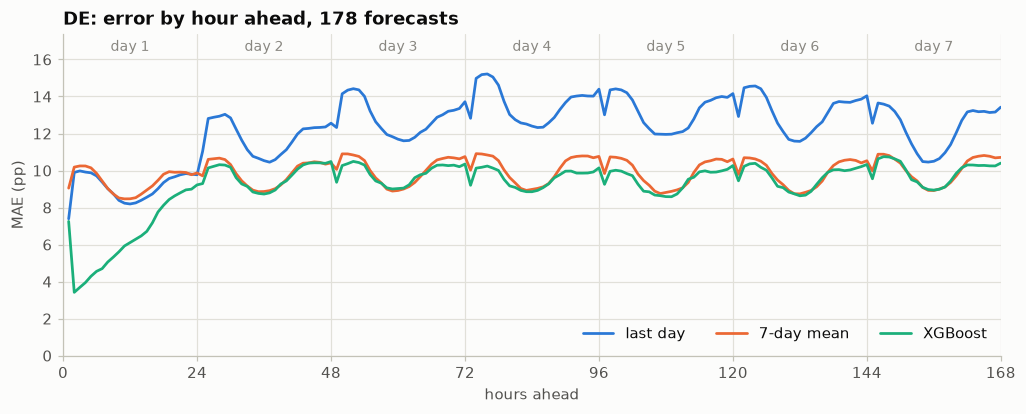

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for name, p in forecasts.items():
    ax.plot(np.arange(1, H + 1), np.abs(p - actual).mean(axis=0), color=COLORS[name], label=name)
ax.set_xlim(0, H)
ax.set_xticks(np.arange(0, H + 1, 24))
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
ax.grid(axis="x")
for k in range(HORIZON_DAYS):
    ax.annotate(f"day {k + 1}", (24 * k + 12, 1), xycoords=("data", "axes fraction"), xytext=(0, -4),
                textcoords="offset points", ha="center", va="top", color=MUTED, fontsize=9)
ax.set_xlabel("hours ahead")
ax.set_ylabel("MAE (pp)")
ax.set_title(f"{REGION}: error by hour ahead, {len(starts)} forecasts")
ax.legend(loc="lower right", ncol=3)
plt.show()

## 7. All regions

The same three forecasts for every region in `CarbonCast/data/`, with one XGBoost fit per region. MAE in percentage points. The last column of the first table is negative where XGBoost beats the best naive baseline; the second table gives the same comparison for each forecast day.

In [10]:
def run_region(region):
    t0 = time.time()
    c = load_cfe(region)
    s, hist, act = make_windows(c)
    m = fit_xgb(c)
    preds = {**{name: f(hist) for name, f in NAIVE.items()}, "XGBoost": xgb_forecast(m, s, hist)}
    print(f"{region}: trees {[x.n_estimators for x in m.values()]}, {time.time() - t0:.0f}s")
    return pd.concat({name: score(act, p) for name, p in preds.items()}, names=["model", "metric"]), act.mean()

regions = sorted(p.name for p in DATA_DIR.iterdir() if (p / f"{p.name}_lifecycle_emissions.csv").exists())
runs = {r: run_region(r) for r in regions}
all_scores = pd.concat({r: s for r, (s, _) in runs.items()}, names=["region"])
all_mae = all_scores.xs("MAE", level="metric")
bar = all_mae[all_mae.index.get_level_values("model").isin(list(NAIVE))].groupby(level="region").min()
bar["all"] = bar[DAYS[:-1]].mean(axis=1)

summary = all_mae["all"].unstack("model")[list(forecasts)].rename_axis(columns=None)
summary.insert(0, "mean %CFE", pd.Series({r: m for r, (_, m) in runs.items()}))
summary["best naive"] = bar["all"]
summary["XGBoost against best naive (%)"] = (summary["XGBoost"] / summary["best naive"] - 1) * 100
display(summary.round(2))
display(((all_mae.xs("XGBoost", level="model") / bar - 1) * 100).round(1).rename_axis("XGBoost against best naive (%)"))
display(all_mae.round(2))

AUS_QLD: trees [47, 8], 4s


BPAT: trees [60, 26], 6s


CISO: trees [80, 11], 5s


DE: trees [68, 44], 7s


ERCO: trees [34, 22], 5s


ES: trees [46, 7], 5s


... (6 outputs left out)

SE: trees [34, 8], 4s


,mean %CFE,last day,7-day mean,XGBoost,best naive,XGBoost against best naive (%)
region,,,,,,
AUS_QLD,18.52,3.74,3.23,3.15,3.23,-2.60
BPAT,87.99,1.80,1.66,1.78,1.64,8.72
CISO,44.16,8.05,7.17,6.39,6.99,-8.54
DE,46.18,12.29,9.90,9.24,9.86,-6.23
ERCO,37.90,12.91,11.30,10.51,11.12,-5.48
ES,63.83,10.09,9.10,8.39,8.85,-5.25
FPL,26.13,2.91,2.80,2.61,2.73,-4.60
ISNE,35.75,5.70,5.43,5.15,5.32,-3.33
NL,18.65,11.30,9.54,8.93,9.46,-5.59


,day 1,day 2,day 3,day 4,day 5,day 6,day 7,all
XGBoost against best naive (%),,,,,,,,
AUS_QLD,-15.1,-0.4,-0.8,-1.0,-0.8,-0.8,-0.6,-2.6
BPAT,-9.2,15.2,12.7,11.2,11.6,9.6,6.6,8.7
CISO,-14.9,-10.4,-9.6,-8.9,-6.8,-5.7,-5.0,-8.5
DE,-29.2,-1.4,-2.1,-4.8,-4.3,-2.3,-1.5,-6.2
ERCO,-11.5,-6.7,-6.7,-5.3,-4.1,-2.8,-2.3,-5.5
ES,-19.9,-3.9,-3.3,-3.3,-3.5,-3.8,-3.8,-5.2
FPL,-11.2,-4.2,-4.4,-4.0,-3.5,-3.5,-3.8,-4.6
ISNE,-10.6,-2.2,-2.0,-2.1,-2.5,-2.9,-3.1,-3.3
NL,-30.3,-1.1,-2.5,-2.3,-3.1,-2.3,-0.7,-5.6


day 1  day 2  day 3  day 4  day 5  day 6  day 7    all
region  model                                                             
AUS_QLD last day     3.05   3.71   3.83   3.85   3.99   3.93   3.84   3.74
        7-day mean   2.94   3.11   3.21   3.29   3.35   3.37   3.38   3.23
        XGBoost      2.50   3.09   3.18   3.26   3.32   3.34   3.35   3.15
BPAT    last day     1.31   1.69   1.86   1.91   1.88   1.94   2.03   1.80
        7-day mean   1.45   1.57   1.64   1.68   1.72   1.76   1.79   1.66
        XGBoost      1.19   1.81   1.85   1.87   1.92   1.93   1.91   1.78
CISO    last day     5.32   7.17   8.12   8.76   9.07   9.14   8.80   8.05
        7-day mean   6.58   7.16   7.44   7.49   7.35   7.15   6.98   7.17
        XGBoost      4.53   6.42   6.73   6.82   6.85   6.74   6.63   6.39
DE      last day     9.14  11.80  12.85  13.60  13.17  13.16  12.30  12.29
        7-day mean   9.43   9.87  10.05  10.09   9.89   9.88  10.08   9.90
        XGBoost      6.48   9.73   9.84   9.61   9.47   9.66   9.93   9.24
ERCO    last day     9.30  11.80  12.37  13.63  14.31  14.47  14.52  12.91
        7-day mean  10.62  11.38  11.52  11.62  11.54  11.37  11.07  11.30
        XGBoost      8.23  10.61  10.75  11.00  11.07  11.06  10.82  10.51
ES      last day     6.28   8.93  10.48  11.62  11.68  10.96  10.68  10.09
        7-day mean   7.99   8.62   8.95   9.18   9.38   9.63   9.94   9.10
        XGBoost      5.03   8.29   8.65   8.88   9.06   9.27   9.56   8.39
FPL     last day     1.86   2.58   2.93   3.17   3.31   3.30   3.21   2.91
        7-day mean   2.34   2.58   2.72   2.84   2.94   3.05   3.15   2.80
        XGBoost      1.65   2.47   2.60   2.72   2.84   2.94   3.03   2.61
ISNE    last day     3.89   5.22   6.01   6.21   6.16   6.18   6.22   5.70
        7-day mean   4.66   5.03   5.28   5.44   5.62   5.88   6.12   5.43
        XGBoost      3.47   4.92   5.18   5.33   5.48   5.71   5.94   5.15
NL      last day     8.41  10.55  11.60  12.48  12.15  12.33  11.57  11.30
        7-day mean   9.01   9.48   9.66   9.74   9.64   9.64   9.64   9.54
        XGBoost      5.86   9.37   9.42   9.52   9.34   9.42   9.58   8.93
NYISO   last day     3.59   5.23   6.07   6.43   6.56   6.50   6.65   5.86
        7-day mean   4.91   5.40   5.78   6.08   6.37   6.67   7.04   6.04
        XGBoost      3.33   5.10   5.54   5.87   6.17   6.46   6.79   5.61
PJM     last day     2.91   4.08   4.48   4.53   4.71   4.49   4.15   4.19
        7-day mean   3.38   3.62   3.74   3.76   3.82   3.91   3.98   3.74
        XGBoost      2.03   3.03   3.13   3.16   3.20   3.23   3.29   3.01
PL      last day     5.65   6.99   7.94   8.32   7.94   7.52   7.71   7.44
        7-day mean   5.89   6.16   6.22   6.20   6.10   6.03   6.10   6.10
        XGBoost      3.74   5.55   5.57   5.59   5.61   5.67   5.76   5.36
SE      last day     0.66   0.85   0.91   0.93   0.98   0.98   0.97   0.90
        7-day mean   0.70   0.75   0.79   0.81   0.84   0.86   0.89   0.81
        XGBoost      0.54   0.75   0.78   0.79   0.82   0.84   0.86   0.77

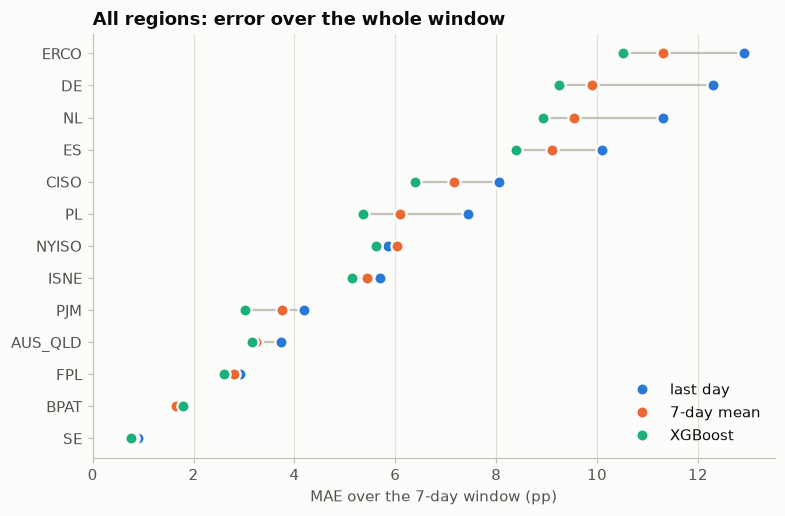

In [11]:
order = summary.sort_values("7-day mean").index                    # hardest region at the top
ypos = np.arange(len(order))
shown = summary.loc[order, list(forecasts)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(ypos, shown.min(axis=1), shown.max(axis=1), color=AXIS, linewidth=1.5, zorder=1)
for name in forecasts:
    ax.plot(shown[name], ypos, "o", color=COLORS[name], markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=name, zorder=2)
ax.set_yticks(ypos, order)
ax.set_xlim(0, None)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE over the 7-day window (pp)")
ax.set_title("All regions: error over the whole window")
ax.legend(loc="lower right")
plt.show()

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
all_scores.round(4).to_csv(OUT_DIR / "scores_by_day.csv")
print("saved", (OUT_DIR / "scores_by_day.csv").relative_to(ROOT))

saved results/cfe_7day_baseline/scores_by_day.csv
